In [122]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import xgboost 
import joblib
import json
from xgboost import XGBClassifier


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import confusion_matrix


In [2]:
df = pd.read_csv(r"C:\ml-churn-api\data\WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
df.shape

(7043, 21)

In [6]:
df.dtypes.value_counts()

str        18
int64       2
float64     1
Name: count, dtype: int64

In [7]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [8]:
df.isnull().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [11]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [12]:
target = df["Churn"].value_counts()*100 / 7043
for i in target:
    print(f"{i:.2f}%",)

73.46%
26.54%


In [13]:
df["TotalCharges"].dtype

<StringDtype(storage='python', na_value=nan)>

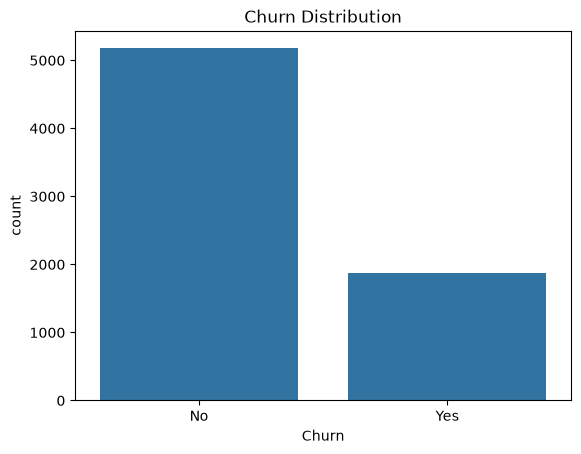

In [14]:
sns.countplot(
    x="Churn",
    data=df
)
plt.title("Churn Distribution")
plt.show()

In [15]:


df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [16]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [17]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [18]:
df[df["TotalCharges"].isnull()]


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [19]:
df = df.drop(columns=["customerID"])

In [20]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [21]:
x = df.drop(columns=["Churn"],)
y = df["Churn"]

In [22]:
y = y.map({
    "No": 0,
    "Yes": 1,})

In [23]:
y.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [24]:
numeric_features = x.select_dtypes(
    include=["int64", "float64"]
).columns

print(numeric_features)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')


In [25]:
categorical_features = x.select_dtypes(
    include=["str"]
).columns

print(categorical_features)

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='str')


In [26]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [27]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

In [28]:
preprocessor = ColumnTransformer([
    (
        "numerical",
        numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

In [29]:
x_processor = preprocessor.fit_transform(x)

In [30]:
x_processor.shape

(7043, 45)

In [31]:
x_train ,x_test ,y_train, y_test = train_test_split(
    x,
    y,
    random_state=42,
    test_size=0.2    ,
    stratify=y
)

In [32]:
print("X_train",x_train.shape)
print("X_test",x_test.shape)

X_train (5634, 19)
X_test (1409, 19)


In [33]:
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))


Training target distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [34]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [35]:
model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specify

In [36]:
y_pred = model.predict(x_test)

In [37]:
y_proba = model.predict_proba(x_test)[:,1] 

In [38]:
accuracy_scores = accuracy_score(y_test,y_pred)

print( "Accuracy_score : " , accuracy_scores)

Accuracy_score :  0.8055358410220014


In [39]:
precision_scores = precision_score(y_test,y_pred)
print("precision_scores : " , precision_scores)

precision_scores :  0.6572327044025157


In [40]:
f1_scores = f1_score(y_test,y_pred)
print("f1_scores : ",f1_scores)

f1_scores :  0.6040462427745664


In [41]:
recall_scores = recall_score(y_test,y_pred)
print("recall_scores : ",recall_scores)

recall_scores :  0.5588235294117647


In [42]:
roc_auc_scores = roc_auc_score(y_test,y_proba)
print("roc_auc_scores : ",roc_auc_scores)

roc_auc_scores :  0.8418610659019866


In [43]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [44]:
cm =  confusion_matrix(y_test,y_pred)

print("Conmfusion Matrix : \n\n", cm )

Conmfusion Matrix : 

 [[926 109]
 [165 209]]


In [45]:
def evaluate_classification_model(model, x_test, y_test):
    y_pred = model.predict(x_test)
    y_prob = model.predict_proba(x_test)[:, 1]

    results = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_prob)
    }

    return results

In [46]:
results = evaluate_classification_model(
    model,
    x_test,
    y_test
)

print(results)

{'accuracy': 0.8055358410220014, 'precision': 0.6572327044025157, 'recall': 0.5588235294117647, 'f1': 0.6040462427745664, 'roc_auc': 0.8418610659019866}


In [47]:
results = evaluate_classification_model(
    model,
    x_test,
    y_test
)

for metric, value in results.items():
    print(f"{metric}: {value:.4f}")

accuracy: 0.8055
precision: 0.6572
recall: 0.5588
f1: 0.6040
roc_auc: 0.8419


RandomFroestClassifier 

In [48]:
rf_model = Pipeline([
    ("Preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
]
)

In [49]:
rf_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specify

In [50]:
rf_results = evaluate_classification_model(
    rf_model,
    x_test,
    y_test
)


In [51]:
for metrics, value in rf_results.items():
    print(f"{metrics}: {value:.4f}")

accuracy: 0.7786
precision: 0.6062
recall: 0.4733
f1: 0.5315
roc_auc: 0.8171


In [52]:
comparsion = pd.DataFrame({
      "Logistic Regression": results,
    "Random Forest": rf_results
})
print(comparsion )

           Logistic Regression  Random Forest
accuracy              0.805536       0.778566
precision             0.657233       0.606164
recall                0.558824       0.473262
f1                    0.604046       0.531532
roc_auc               0.841861       0.817132


In [53]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [54]:
cv_results_lr = cross_validate(
    model,
    x_train,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ],
    n_jobs=-1
)

In [55]:
for metric in [
    "test_accuracy",
    "test_precision",
    "test_recall",
    "test_f1",
    "test_roc_auc"
]:
    scores = cv_results_lr[metric]

    print(
        f"{metric}: "
        f"{scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )

test_accuracy: 0.8021 +/- 0.0116
test_precision: 0.6529 +/- 0.0255
test_recall: 0.5431 +/- 0.0411
test_f1: 0.5923 +/- 0.0296
test_roc_auc: 0.8461 +/- 0.0125


In [56]:
cv_results_rf = cross_validate(
    rf_model,
    x_train,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ],
    n_jobs=-1
)

In [57]:
for metric in [
    "test_accuracy",
    "test_precision",
    "test_recall",
    "test_f1",
    "test_roc_auc"
]:
    scores = cv_results_rf[metric]

    print(
        f"{metric}: "
        f"{scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )

test_accuracy: 0.7861 +/- 0.0124
test_precision: 0.6260 +/- 0.0337
test_recall: 0.4849 +/- 0.0216
test_f1: 0.5462 +/- 0.0234
test_roc_auc: 0.8205 +/- 0.0121


In [58]:
cv_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    
    "Logistic Regression Mean": [
        cv_results_lr["test_accuracy"].mean(),
        cv_results_lr["test_precision"].mean(),
        cv_results_lr["test_recall"].mean(),
        cv_results_lr["test_f1"].mean(),
        cv_results_lr["test_roc_auc"].mean()
    ],
    
    "Random Forest Mean": [
        cv_results_rf["test_accuracy"].mean(),
        cv_results_rf["test_precision"].mean(),
        cv_results_rf["test_recall"].mean(),
        cv_results_rf["test_f1"].mean(),
        cv_results_rf["test_roc_auc"].mean()
    ]
})

print(cv_comparison)

      Metric  Logistic Regression Mean  Random Forest Mean
0   Accuracy                  0.802096            0.786123
1  Precision                  0.652899            0.625952
2     Recall                  0.543144            0.484950
3         F1                  0.592316            0.546212
4    ROC-AUC                  0.846137            0.820508


In [59]:
print( xgboost.__version__)

3.4.1


In [60]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

In [61]:
xgb_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specify

In [62]:
xgb_results = evaluate_classification_model(
    xgb_model,
    x_test,
    y_test
)

In [63]:
for metric, value in xgb_results.items():
    print(f"{metric}: {value:.4f}")

accuracy: 0.8020
precision: 0.6610
recall: 0.5214
f1: 0.5830
roc_auc: 0.8423


In [64]:
model_comparison = pd.DataFrame({
    "Logistic Regression": results,
    "Random Forest": rf_results,
    "XGBoost": xgb_results
})

print(model_comparison)

           Logistic Regression  Random Forest   XGBoost
accuracy              0.805536       0.778566  0.801987
precision             0.657233       0.606164  0.661017
recall                0.558824       0.473262  0.521390
f1                    0.604046       0.531532  0.582960
roc_auc               0.841861       0.817132  0.842330


In [65]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

In [66]:
param_distributions = {
    "classifier__n_estimators": [
        200,
        300,
        500,
        700
    ],

    "classifier__learning_rate": [
        0.01,
        0.03,
        0.05,
        0.1
    ],

    "classifier__max_depth": [
        3,
        4,
        5,
        6
    ],

    "classifier__min_child_weight": [
        1,
        3,
        5
    ],

    "classifier__subsample": [
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "classifier__colsample_bytree": [
        0.7,
        0.8,
        0.9,
        1.0
    ]
}

In [67]:
random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="f1",
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

In [68]:
random_search.fit(x_train,y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': [0.7, 0.8, ...], 'classifier__learning_rate': [0.01, 0.03, ...], 'classifier__max_depth': [3, 4, ...], 'classifier__min_child_weight': [1, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximu

In [69]:
print(random_search.best_params_)

{'classifier__subsample': 0.7, 'classifier__n_estimators': 200, 'classifier__min_child_weight': 5, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 0.8}


In [70]:
print(random_search.best_score_)

0.5920315531644528


In [71]:
best_xgb_model = random_search.best_estimator_

In [72]:
tuned_xgb_results = evaluate_classification_model(
    best_xgb_model,
    x_test,
    y_test
)

In [73]:
for metric, value in tuned_xgb_results.items():
    print(f"{metric}: {value:.4f}")

accuracy: 0.8027
precision: 0.6633
recall: 0.5214
f1: 0.5838
roc_auc: 0.8476


In [74]:
final_comparison = pd.DataFrame({
    "Logistic Regression": results,
    "Random Forest": rf_results,
    "XGBoost": xgb_results,
    "Tuned XGBoost": tuned_xgb_results
})

print(final_comparison)

           Logistic Regression  Random Forest   XGBoost  Tuned XGBoost
accuracy              0.805536       0.778566  0.801987       0.802697
precision             0.657233       0.606164  0.661017       0.663265
recall                0.558824       0.473262  0.521390       0.521390
f1                    0.604046       0.531532  0.582960       0.583832
roc_auc               0.841861       0.817132  0.842330       0.847599


In [75]:
lr_prob = model.predict_proba(x_test)[:, 1]

rf_prob = rf_model.predict_proba(x_test)[:, 1]

xgb_prob = xgb_model.predict_proba(x_test)[:, 1]

tuned_xgb_prob = best_xgb_model.predict_proba(x_test)[:, 1]

In [77]:
lr_pred = (lr_prob >= 0.50).astype(int)

cm_lr = confusion_matrix(y_test, lr_pred)

print(cm_lr)

[[926 109]
 [165 209]]


In [78]:
tn, fp, fn, tp = confusion_matrix(
    y_test,
    lr_pred
).ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)



True Negatives : 926
False Positives: 109
False Negatives: 165
True Positives : 209


In [81]:
error_analysis = x_test.copy()
error_analysis["actual"] = y_test.values
error_analysis["predicted"] = lr_pred
error_analysis["probability"] = lr_prob

In [85]:
false_negatives = error_analysis[(
    error_analysis["actual"] == 1 ) &(
    error_analysis["predicted"] == 0
    )
]

false_negatives.tail()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,actual,predicted,probability
595,Female,0,No,No,12,Yes,Yes,DSL,Yes,No,...,No,No,Month-to-month,Yes,Mailed check,61.65,713.75,1,0,0.239705
481,Female,0,Yes,No,48,No,No phone service,DSL,Yes,No,...,No,Yes,Month-to-month,Yes,Bank transfer (automatic),45.30,2145.00,1,0,0.130335
610,Male,0,Yes,Yes,9,No,No phone service,DSL,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,29.95,248.95,1,0,0.474396
1477,Male,0,Yes,Yes,61,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,One year,Yes,Electronic check,106.00,6547.70,1,0,0.184982
3737,Female,0,No,No,5,Yes,Yes,DSL,No,No,...,No,No,Month-to-month,Yes,Mailed check,50.60,249.95,1,0,0.464996


In [86]:
false_negatives = error_analysis[(
    error_analysis["actual"] == 1 ) &(
    error_analysis["predicted"] == 0
    )
]

false_negatives.tail()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,actual,predicted,probability
595,Female,0,No,No,12,Yes,Yes,DSL,Yes,No,...,No,No,Month-to-month,Yes,Mailed check,61.65,713.75,1,0,0.239705
481,Female,0,Yes,No,48,No,No phone service,DSL,Yes,No,...,No,Yes,Month-to-month,Yes,Bank transfer (automatic),45.30,2145.00,1,0,0.130335
610,Male,0,Yes,Yes,9,No,No phone service,DSL,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,29.95,248.95,1,0,0.474396
1477,Male,0,Yes,Yes,61,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,One year,Yes,Electronic check,106.00,6547.70,1,0,0.184982
3737,Female,0,No,No,5,Yes,Yes,DSL,No,No,...,No,No,Month-to-month,Yes,Mailed check,50.60,249.95,1,0,0.464996


In [88]:
false_positives = error_analysis[(
    error_analysis["actual"] == 0 ) &(
    error_analysis["predicted"] == 1
    )
]

false_positives.tail()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,actual,predicted,probability
2150,Male,0,No,No,21,Yes,Yes,Fiber optic,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,84.10,1737.45,0,1,0.683447
3885,Female,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,74.95,212.40,0,1,0.744948
5110,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,73.50,632.20,0,1,0.719733
935,Female,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,...,Yes,No,Month-to-month,Yes,Electronic check,83.25,308.05,0,1,0.812555
4223,Male,0,No,No,3,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Mailed check,70.30,220.40,0,1,0.621236


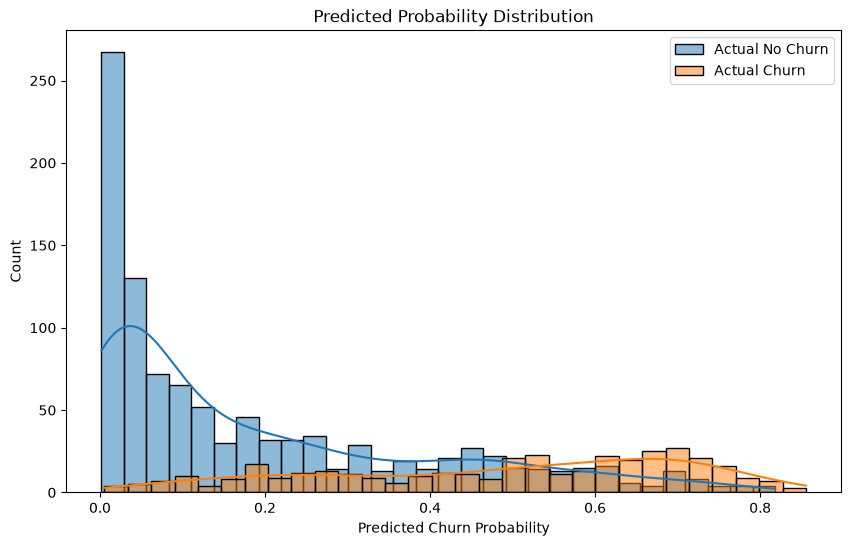

In [90]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=lr_prob[y_test.values == 0],
    bins=30,
    kde=True,
    label="Actual No Churn"
)

sns.histplot(
    data=lr_prob[y_test.values == 1],
    bins=30,
    kde=True,
    label="Actual Churn"
)

plt.xlabel("Predicted Churn Probability")
plt.ylabel("Count")
plt.title("Predicted Probability Distribution")
plt.legend()
plt.show()

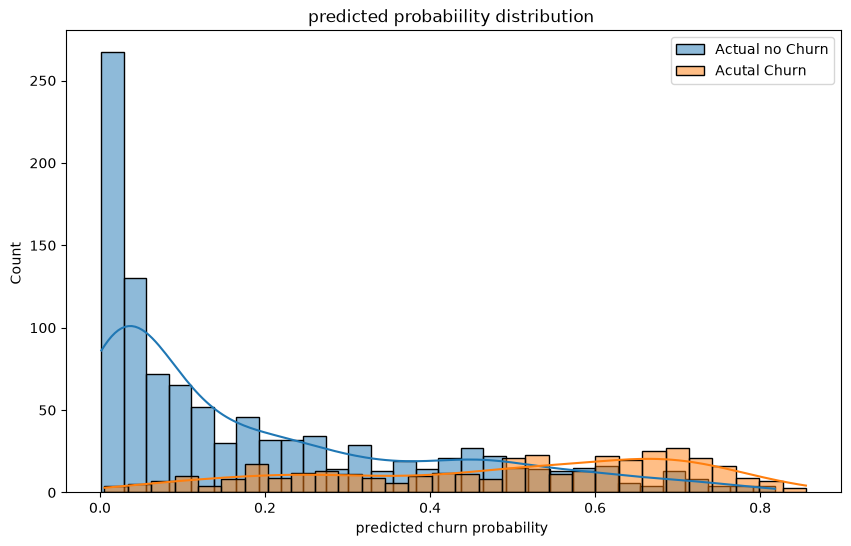

In [91]:
plt.figure(figsize=(10,6))

sns.histplot(
    data= lr_prob[y_test.values == 0],
    bins=30 ,
    kde= True,
    label= "Actual no Churn"
)
sns.histplot(
    data= lr_prob[y_test.values == 1 ],
    bins= 30 ,
    kde = True ,
    label= "Acutal Churn "
)

plt.xlabel("predicted churn probability ")
plt.ylabel ("Count ")
plt.title("predicted probabiility distribution ")
plt.legend()
plt.show ()

In [94]:
thresholds = np. arange(
    0.20,
    0.71,
    0.05
)

threshold_results = []

for threshold in thresholds:

    predictions = (
        lr_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_test,
            predictions
        ),
        "recall": recall_score(
            y_test,
            predictions
        ),
        "f1": f1_score(
            y_test,
            predictions
        )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

print(threshold_df)


    threshold  precision    recall        f1
0        0.20   0.467153  0.855615  0.604344
1        0.25   0.498355  0.810160  0.617108
2        0.30   0.519337  0.754011  0.615049
3        0.35   0.544330  0.705882  0.614668
4        0.40   0.569476  0.668449  0.615006
5        0.45   0.600522  0.614973  0.607662
6        0.50   0.657233  0.558824  0.604046
7        0.55   0.678431  0.462567  0.550079
8        0.60   0.717703  0.401070  0.514580
9        0.65   0.746753  0.307487  0.435606
10       0.70   0.739130  0.181818  0.291845


In [95]:
best_threshold_row = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

print(best_threshold_row)

threshold    0.250000
precision    0.498355
recall       0.810160
f1           0.617108
Name: 1, dtype: float64


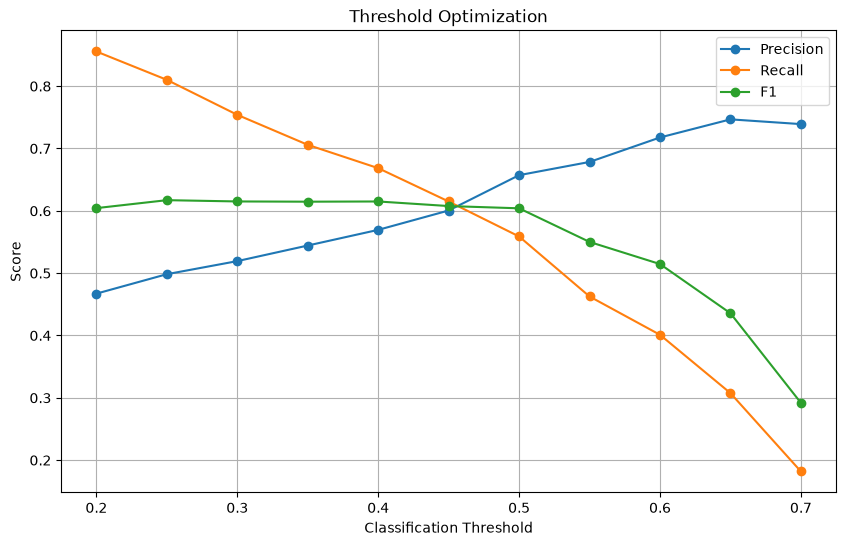

In [96]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Optimization")
plt.legend()
plt.grid()
plt.show()

In [97]:
xgb_threshold_results = []

for threshold in thresholds:

    predictions = (
        tuned_xgb_prob >= threshold
    ).astype(int)

    xgb_threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_test,
            predictions
        ),
        "recall": recall_score(
            y_test,
            predictions
        ),
        "f1": f1_score(
            y_test,
            predictions
        )
    })

xgb_threshold_df = pd.DataFrame(
    xgb_threshold_results
)

print(xgb_threshold_df)

    threshold  precision    recall        f1
0        0.20   0.478852  0.847594  0.611969
1        0.25   0.506734  0.804813  0.621901
2        0.30   0.532075  0.754011  0.623894
3        0.35   0.557851  0.721925  0.629371
4        0.40   0.587952  0.652406  0.618504
5        0.45   0.626062  0.590909  0.607978
6        0.50   0.663265  0.521390  0.583832
7        0.55   0.714876  0.462567  0.561688
8        0.60   0.733333  0.382353  0.502636
9        0.65   0.765101  0.304813  0.435946
10       0.70   0.803279  0.262032  0.395161


In [99]:
best_xgb_threshold = xgb_threshold_df.loc[
    xgb_threshold_df["f1"].idxmax()
]

print(best_xgb_threshold)

threshold    0.350000
precision    0.557851
recall       0.721925
f1           0.629371
Name: 3, dtype: float64


In [100]:
final_results = evaluate_classification_model(
    model,
    x_test,
    y_test
)

print(final_results)

{'accuracy': 0.8055358410220014, 'precision': 0.6572327044025157, 'recall': 0.5588235294117647, 'f1': 0.6040462427745664, 'roc_auc': 0.8418610659019866}


In [101]:
final_results = evaluate_classification_model(
    rf_model,
    x_test,
    y_test
)

print(final_results)

{'accuracy': 0.7785663591199432, 'precision': 0.6061643835616438, 'recall': 0.4732620320855615, 'f1': 0.5315315315315315, 'roc_auc': 0.817131674804309}


In [102]:
final_results = evaluate_classification_model(
    xgb_model,
    x_test,
    y_test
)

print(final_results)

{'accuracy': 0.8019872249822569, 'precision': 0.6610169491525424, 'recall': 0.5213903743315508, 'f1': 0.5829596412556054, 'roc_auc': 0.8423299491074426}


In [107]:
best_threshold_row

threshold    0.250000
precision    0.498355
recall       0.810160
f1           0.617108
Name: 1, dtype: float64

In [108]:
# Best F1 from each model
best_lr = threshold_results[
    threshold_results["model"] == "Logistic Regression"
]["f1"].max()

best_xgb = threshold_results[
    threshold_results["model"] == "Tuned XGBoost"
]["f1"].max()

print("Logistic Regression Best F1:", best_lr)
print("Tuned XGBoost Best F1:", best_xgb)

TypeError: list indices must be integers or slices, not str

In [109]:
threshold_results = pd.DataFrame(threshold_results)

In [112]:
lr_thresholds = np.arange(0.10, 0.71, 0.01)

lr_results = []

for threshold in lr_thresholds:
    lr_pred = (lr_prob >= threshold).astype(int)

    lr_results.append({
        "threshold": threshold,
        "precision": precision_score(y_test, lr_pred),
        "recall": recall_score(y_test, lr_pred),
        "f1": f1_score(y_test, lr_pred)
    })

lr_threshold_df = pd.DataFrame(lr_results)

best_lr_row = lr_threshold_df.loc[
    lr_threshold_df["f1"].idxmax()
]

print("Best Logistic Regression:")
print(best_lr_row)

Best Logistic Regression:
threshold    0.280000
precision    0.517730
recall       0.780749
f1           0.622601
Name: 18, dtype: float64


In [113]:
xgb_thresholds = np.arange(0.10, 0.71, 0.01)

xgb_results = []

for threshold in xgb_thresholds:
    xgb_pred = (tuned_xgb_prob >= threshold).astype(int)

    xgb_results.append({
        "threshold": threshold,
        "precision": precision_score(y_test, xgb_pred),
        "recall": recall_score(y_test, xgb_pred),
        "f1": f1_score(y_test, xgb_pred)
    })

xgb_threshold_df = pd.DataFrame(xgb_results)

best_xgb_row = xgb_threshold_df.loc[
    xgb_threshold_df["f1"].idxmax()
]

print("Best Tuned XGBoost:")
print(best_xgb_row)

Best Tuned XGBoost:
threshold    0.290000
precision    0.532348
recall       0.770053
f1           0.629508
Name: 19, dtype: float64


In [115]:
print("Logistic Regression F1:", best_lr_row["f1"])
print("Tuned XGBoost F1:", best_xgb_row["f1"])

Logistic Regression F1: 0.6226012793176973
Tuned XGBoost F1: 0.6295081967213115


In [116]:
final_model = best_xgb_model

In [118]:
FINAL_MODEL = best_xgb_model
FINAL_THRESHOLD = best_xgb_row["threshold"]

print("Final Model: Tuned XGBoost")
print("Final Threshold:", FINAL_THRESHOLD)
print("Final F1:", best_xgb_row["f1"])

Final Model: Tuned XGBoost
Final Threshold: 0.2899999999999999
Final F1: 0.6295081967213115


In [119]:
final_results = evaluate_classification_model(
    final_model,
    x_test,
    y_test
)

print(final_results)

{'accuracy': 0.8026969481902059, 'precision': 0.6632653061224489, 'recall': 0.5213903743315508, 'f1': 0.5838323353293413, 'roc_auc': 0.8475987496447853}


In [120]:
joblib.dump(
    final_model,
    "C:\\ml-churn-api\\models\\churn_model.joblib"
)

['C:\\ml-churn-api\\models\\churn_model.joblib']

In [123]:
metadata = {
    "model_type": type(
        final_model.named_steps["classifier"]
    ).__name__,
    "threshold": FINAL_THRESHOLD,
    "target": "Churn",
    "positive_class": 1,
    "negative_class": 0,
    "metrics": {
        "accuracy": float(final_results["accuracy"]),
        "precision": float(final_results["precision"]),
        "recall": float(final_results["recall"]),
        "f1": float(final_results["f1"]),
        "roc_auc": float(final_results["roc_auc"])
    }
}

In [124]:
with open(
    "C:\\ml-churn-api\\models\\metadata.json",
    "w"
) as f:
    json.dump(
        metadata,
        f,
        indent=4
    )

In [125]:
loaded_model = joblib.load(
    "C:\\ml-churn-api\\models\\churn_model.joblib"
)

In [126]:
with open(
    "C:\\ml-churn-api\\models\\metadata.json",
    "r"
) as f:
    loaded_metadata = json.load(f)

In [127]:
loaded_probabilities = (
    loaded_model.predict_proba(x_test)[:, 1]
)

In [128]:
loaded_predictions = (
    loaded_probabilities >= FINAL_THRESHOLD
).astype(int)

In [129]:
loaded_f1 = f1_score(
    y_test,
    loaded_predictions
)

print("Loaded model F1:", loaded_f1)

Loaded model F1: 0.6295081967213115


In [130]:
def predict_churn(
    model,
    data,
    threshold
):
    probability = model.predict_proba(data)[:, 1]

    prediction = (
        probability >= threshold
    ).astype(int)

    return prediction, probability

In [132]:
predictions, probabilities = predict_churn(
    loaded_model,
    x_test,
    FINAL_THRESHOLD
)

In [134]:
sample = x_test.iloc[[0]]

In [135]:
prediction, probability = predict_churn(
    loaded_model,
    sample,
    FINAL_THRESHOLD
)

print("Probability:", probability[0])
print("Prediction:", prediction[0])

Probability: 0.023590129
Prediction: 0


In [136]:
print(
    "F1:",
    f1_score(y_test, predictions)
)

F1: 0.6295081967213115


In [ ]:
with open("models/metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)